# <center> ML LAB -7 </center>

# Lab-7: To implement the Naïve Bayes Classification algorithm using suitable dataset.

## Dataset Used : bank_notes.csv

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,
                             confusion_matrix,ConfusionMatrixDisplay)
pd.set_option('display.max_columns',None)

In [2]:
df=pd.read_csv('bank_notes.csv')

In [3]:
df.head()

,variance,skewness,curtosis,entropy,Target
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [4]:
df.tail()

,variance,skewness,curtosis,entropy,Target
1367,0.40614,1.34920,-1.4501,-0.55949,1
1368,-1.38870,-4.87730,6.4774,0.34179,1
1369,-3.75030,-13.45860,17.5932,-2.77710,1
1370,-3.56370,-8.38270,12.3930,-1.28230,1
1371,-2.54190,-0.65804,2.6842,1.19520,1


In [5]:
df.shape

(1372, 5)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   Target    1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [7]:
df.describe()

,variance,skewness,curtosis,entropy,Target
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [8]:
df.isnull().sum()

variance    0
skewness    0
curtosis    0
entropy     0
Target      0
dtype: int64

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
variance,1372.0,0.433735,2.842763,-7.0421,-1.773000,0.49618,2.821475,6.8248
skewness,1372.0,1.922353,5.869047,-13.7731,-1.708200,2.31965,6.814625,12.9516
curtosis,1372.0,1.397627,4.310030,-5.2861,-1.574975,0.61663,3.179250,17.9274
entropy,1372.0,-1.191657,2.101013,-8.5482,-2.413450,-0.58665,0.394810,2.4495
Target,1372.0,0.444606,0.497103,0.0000,0.000000,0.00000,1.000000,1.0000


In [10]:
df.duplicated().sum()

np.int64(24)

In [11]:
df.drop_duplicates(inplace=True)

In [12]:
df.dtypes

variance    float64
skewness    float64
curtosis    float64
entropy     float64
Target        int64
dtype: object

In [13]:
df.columns

Index(['variance', 'skewness', 'curtosis', 'entropy', 'Target'], dtype='object')

In [14]:
df['Target'].unique()

array([0, 1])

In [15]:
df['Target'].value_counts()

Target
0    738
1    610
Name: count, dtype: int64

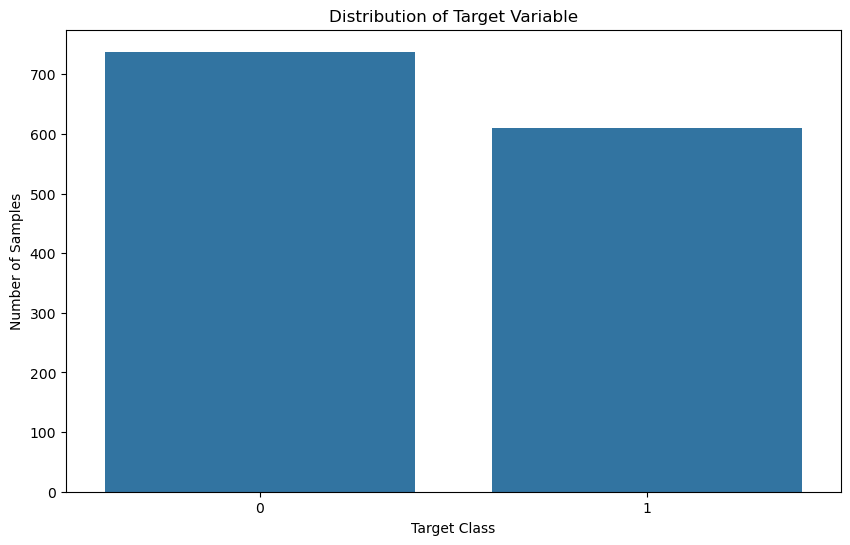

In [16]:
plt.figure(figsize=(10,6))
sns.countplot(x='Target',data=df)
plt.title("Distribution of Target Variable")
plt.xlabel("Target Class")
plt.ylabel("Number of Samples")
plt.show()

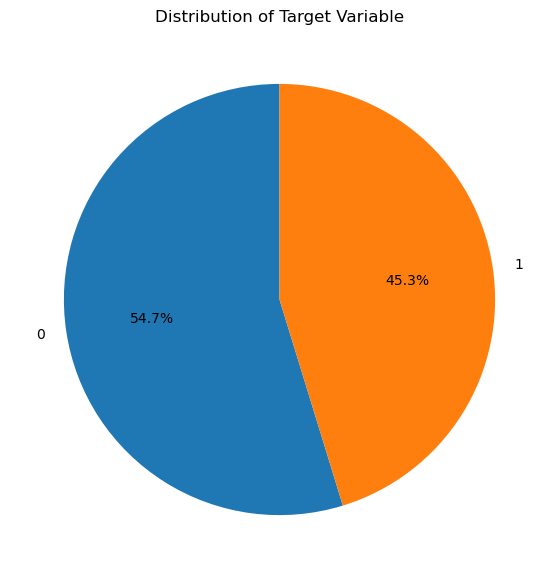

In [17]:
class_counts = df['Target'].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Target Variable')
plt.show()

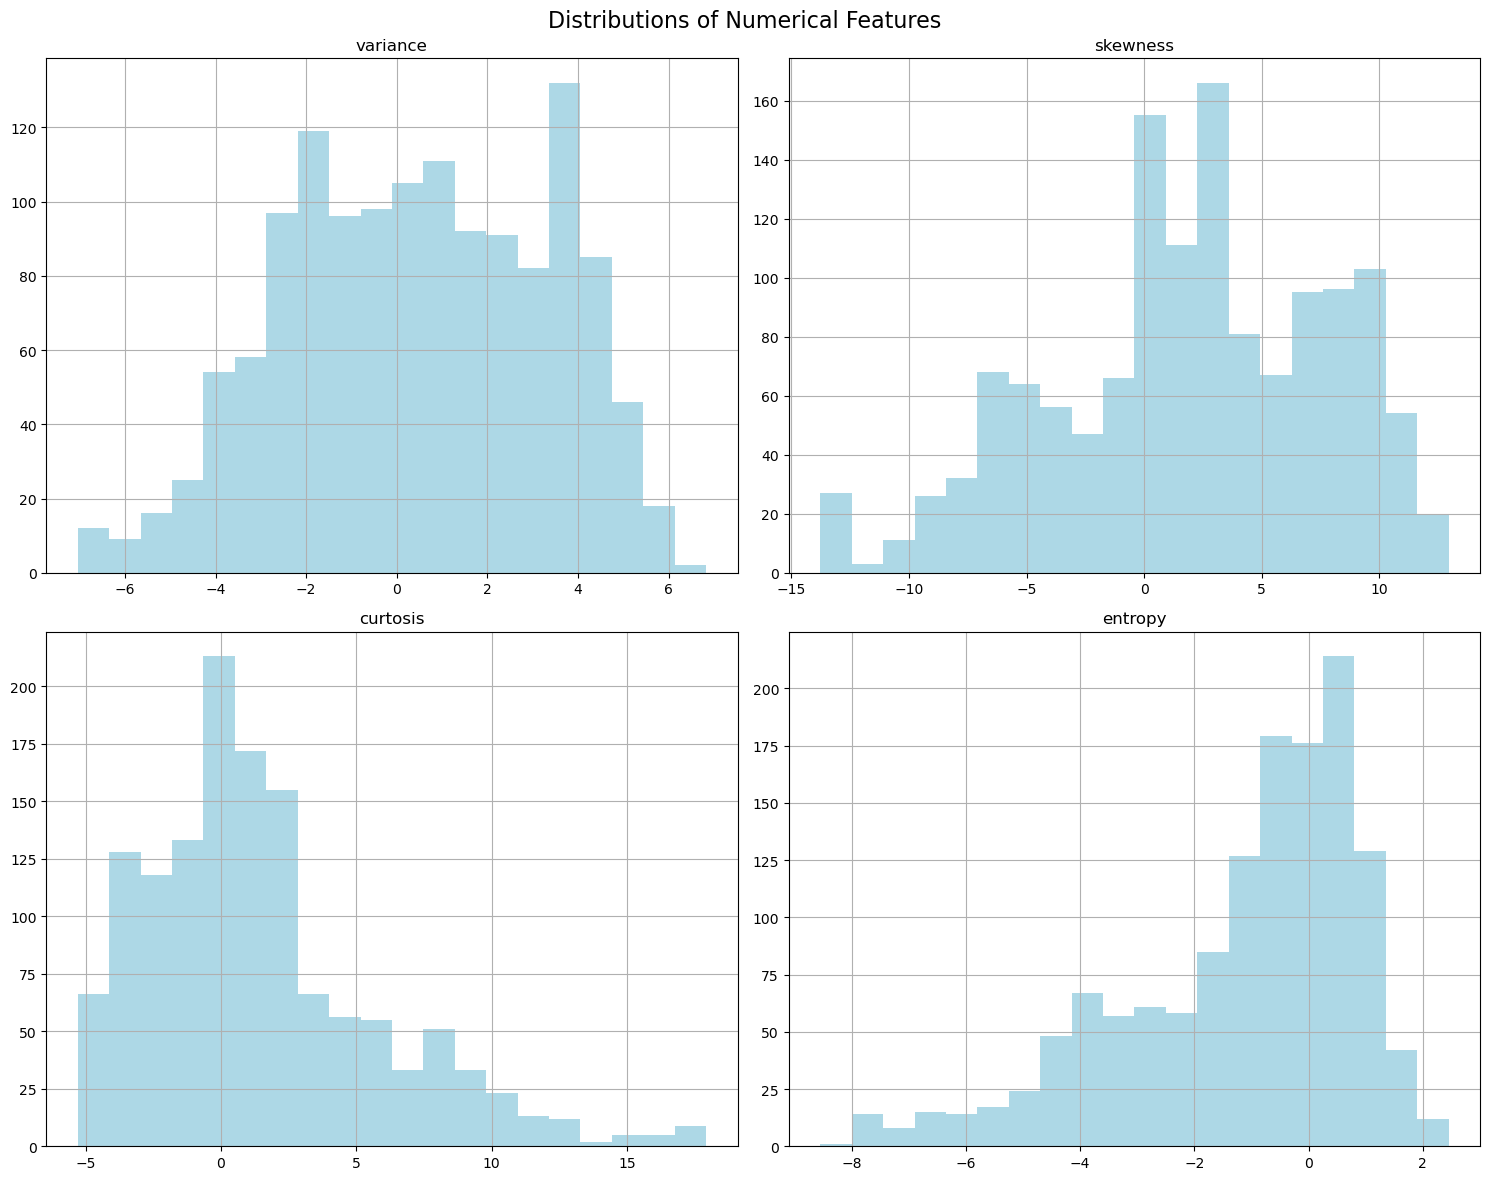

In [18]:
numerical_features = ['variance', 'skewness', 'curtosis', 'entropy']
df[numerical_features].hist(figsize=(15,12),bins=20,color='lightblue')
plt.suptitle('Distributions of Numerical Features',fontsize=16,)
plt.tight_layout()
plt.show()

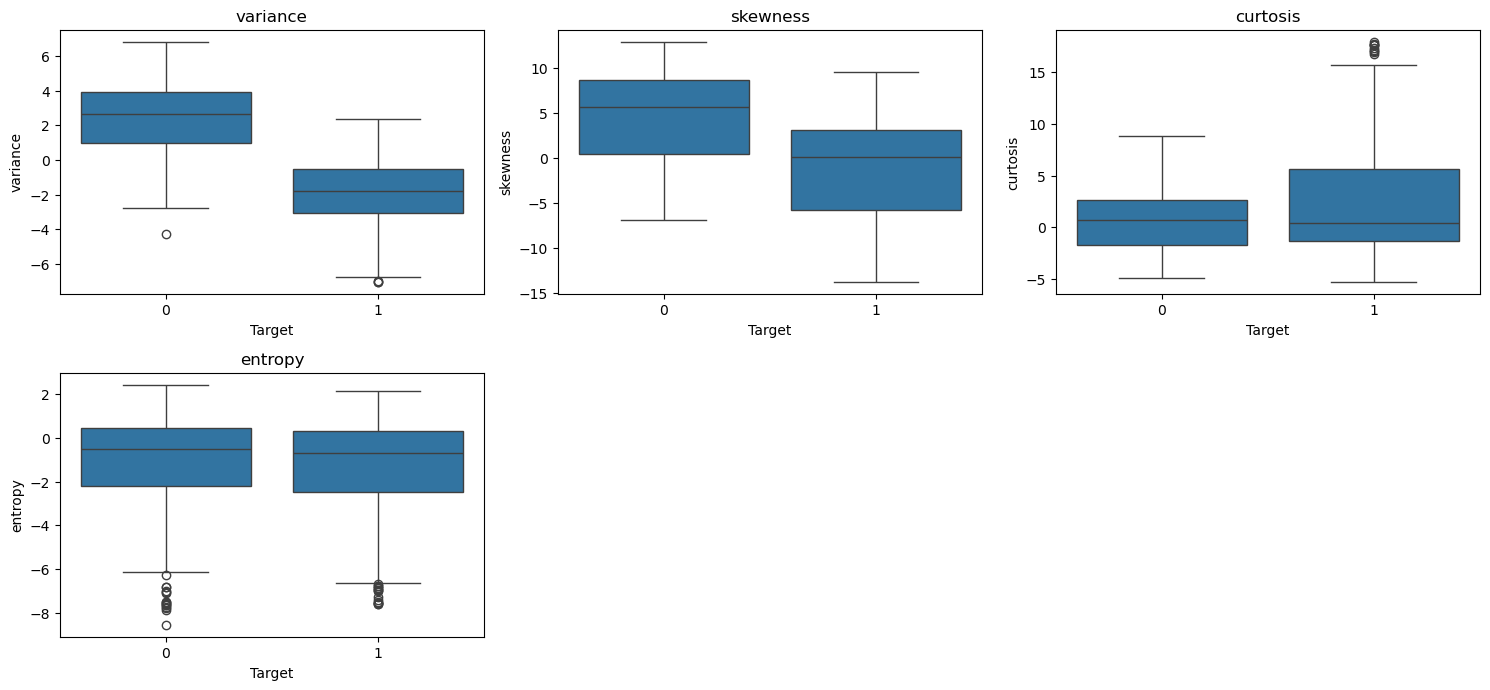

In [19]:
plt.figure(figsize=(15,10))
for i, column in enumerate(numerical_features,1):
    plt.subplot(3,3,i)
    sns.boxplot(x='Target',y=column,data=df)
    plt.title(column)
plt.tight_layout()
plt.show()

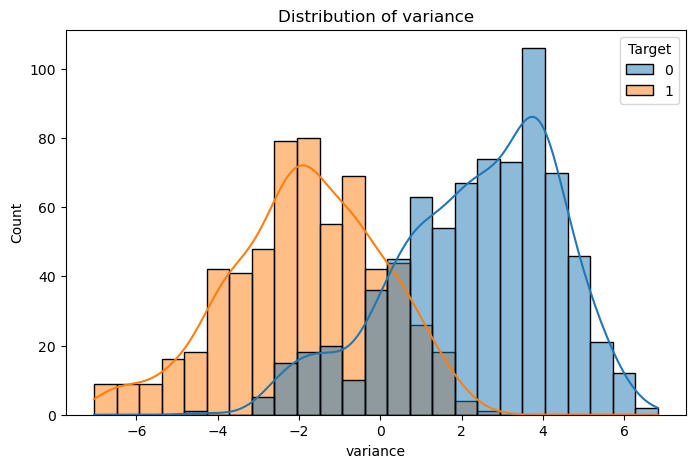

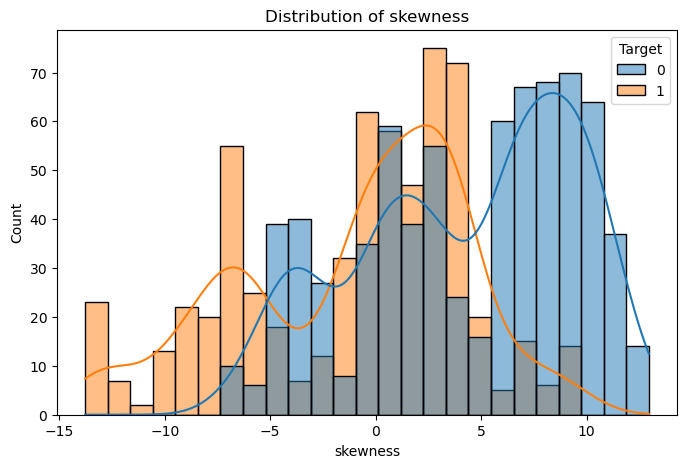

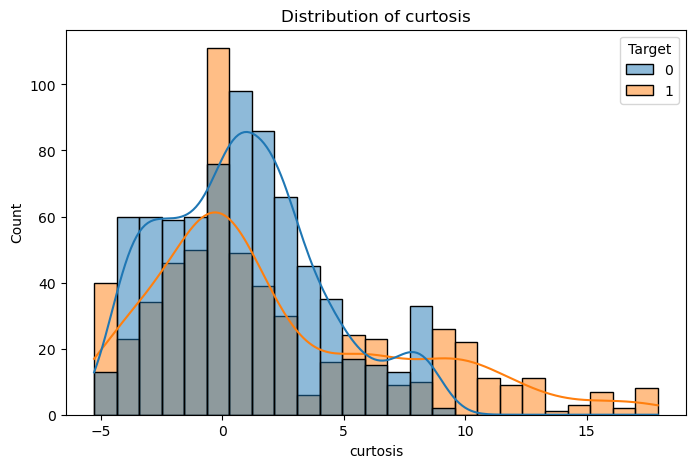

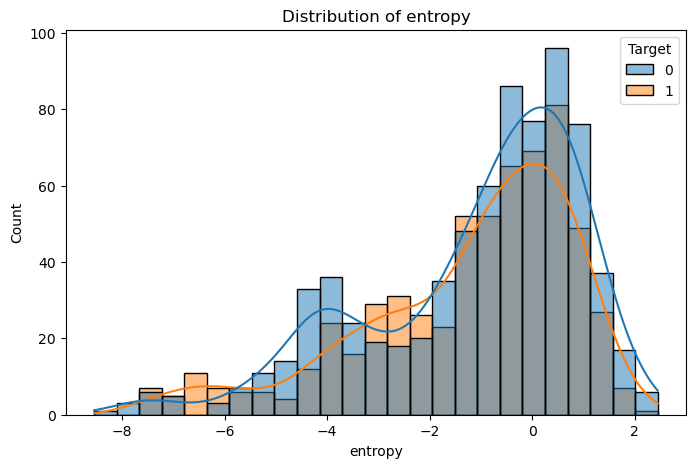

In [20]:
for column in numerical_features:
  plt.figure(figsize=(8,5))
  sns.histplot(data=df,x=column,hue='Target',kde=True,bins=25)
  plt.title(f'Distribution of {column}')
  plt.show()

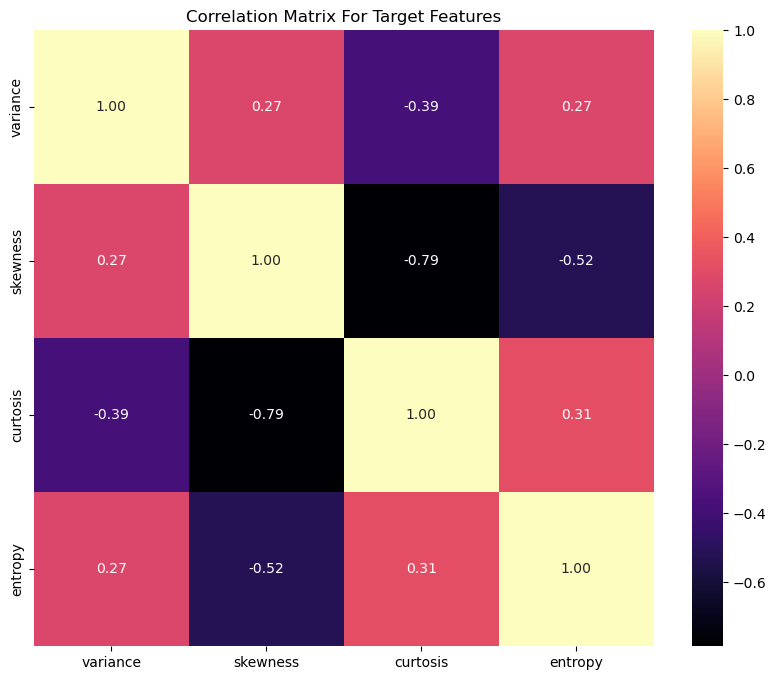

In [21]:
correlation_matrix=df[numerical_features].corr()
plt.figure(figsize=(10,8))
sns.heatmap(correlation_matrix,annot=True,fmt=".2f",cmap='magma')
plt.title('Correlation Matrix For Target Features')
plt.show()

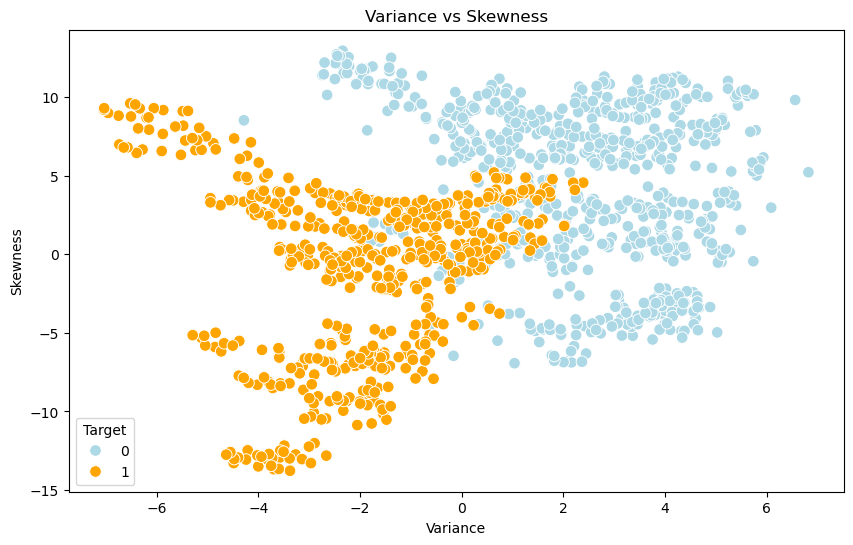

In [22]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x='variance',y='skewness',palette={0: 'lightBlue',1: 'Orange'},hue='Target',s=70)
plt.title('Variance vs Skewness')
plt.xlabel('Variance')
plt.ylabel('Skewness')
plt.show()

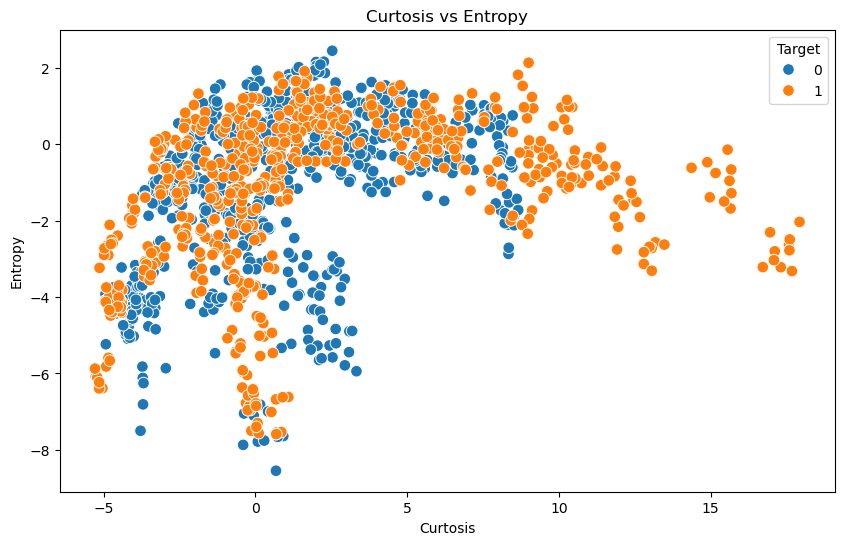

In [23]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x='curtosis',y='entropy',hue='Target',s=70)
plt.title('Curtosis vs Entropy')
plt.xlabel('Curtosis')
plt.ylabel('Entropy')
plt.show()

In [24]:
label_encoder=LabelEncoder()
df['Target_encoded']=label_encoder.fit_transform(df['Target'])
print(df[['Target','Target_encoded']].head(10))

   Target  Target_encoded
0       0               0
1       0               0
2       0               0
3       0               0
4       0               0
5       0               0
6       0               0
7       0               0
8       0               0
9       0               0


In [25]:
print("Target mapping:")
for index, target_name in enumerate(label_encoder.classes_):
  print(f"{index}: {target_name}")

Target mapping:
0: 0
1: 1


In [26]:
X=df[numerical_features]
y=df['Target_encoded']
print('X Shape:',X.shape)
print('y Shape:',y.shape)

X Shape: (1348, 4)
y Shape: (1348,)


In [27]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training Samples:",X_train.shape[0])
print("Testing Samples:",X_test.shape[0])

Training Samples: 1078
Testing Samples: 270


# GaussianNB

In [28]:
GaussianNB()

GaussianNB()

In [29]:
gnb=GaussianNB()
gnb.fit(X_train,y_train)

GaussianNB()

In [30]:
y_pred=gnb.predict(X_test)
print("Predicated labels:")
print(y_pred)

Predicated labels:
[0 1 1 0 1 1 0 0 1 1 0 0 1 1 0 1 1 0 1 0 1 1 1 0 0 1 0 1 0 0 1 0 1 0 1 0 1
 1 1 0 0 1 0 0 1 0 0 1 0 0 1 0 0 1 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 1 0 1 1 1 0 1 1 0 1 0 1 1 1 1 1 0 1 1 0 0 0 1 0 0 0 1 0 0 0 1 0 1 1
 0 1 0 0 0 0 0 1 1 1 0 1 0 0 1 1 0 0 1 1 1 1 0 1 0 0 0 1 0 0 1 0 0 1 0 1 1
 1 1 1 1 1 0 1 1 1 0 1 0 1 0 1 0 1 1 1 0 1 1 0 0 1 0 1 0 1 1 0 1 0 1 1 1 1
 0 0 1 1 0 1 0 0 0 1 0 0 0 0 1 0 0 1 0 1 0 1 0 0 1 0 0 1 1 1 0 0 0 1 0 1 0
 1 0 1 0 0 1 0 1 1 0 0 0 1 1 0 0 1 1 0 1 1 1 1 0 1 1 1 1 1 1 1 0 1 0 0 0 0
 0 0 0 0 1 1 0 0 1 0 0]


In [31]:
comparison=pd.DataFrame({"Actual":y_test.values,"Predicted":y_pred})
print(comparison.head(5))

   Actual  Predicted
0       0          0
1       1          1
2       0          1
3       0          0
4       1          1


In [32]:
comparison["Actual_Target"]=label_encoder.inverse_transform(comparison["Actual"])
comparison["Predicted_Target"]=label_encoder.inverse_transform(comparison["Predicted"])
print(comparison.head(5))

   Actual  Predicted  Actual_Target  Predicted_Target
0       0          0              0                 0
1       1          1              1                 1
2       0          1              0                 1
3       0          0              0                 0
4       1          1              1                 1


In [33]:
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)
print("Accuracy (%):",accuracy*100)

Accuracy: 0.8444444444444444
Accuracy (%): 84.44444444444444


In [34]:
precision=precision_score(y_test,y_pred)
print("Precision:",precision)
print("Precision (%):",precision*100)

Precision: 0.8076923076923077
Precision (%): 80.76923076923077


In [35]:
recall=recall_score(y_test,y_pred)
print("Recall:",recall)
print("Recall (%):",recall*100)

Recall: 0.860655737704918
Recall (%): 86.0655737704918


In [36]:
f1=f1_score(y_test,y_pred)
print("F1 Score:",f1)
print("F1 Score (%):",f1*100)

F1 Score: 0.8333333333333334
F1 Score (%): 83.33333333333334


In [37]:
print("=== MODEL PERFORMANCE ===")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

=== MODEL PERFORMANCE ===
Accuracy : 0.8444
Precision : 0.8077
Recall : 0.8607
F1 Score : 0.8333


In [38]:
print("Classification Report:")
print(classification_report(y_test,y_pred,target_names=[str(c) for c in label_encoder.classes_]))

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.83      0.85       148
           1       0.81      0.86      0.83       122

    accuracy                           0.84       270
   macro avg       0.84      0.85      0.84       270
weighted avg       0.85      0.84      0.84       270



In [39]:
cm=confusion_matrix(y_test,y_pred)
print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[123  25]
 [ 17 105]]


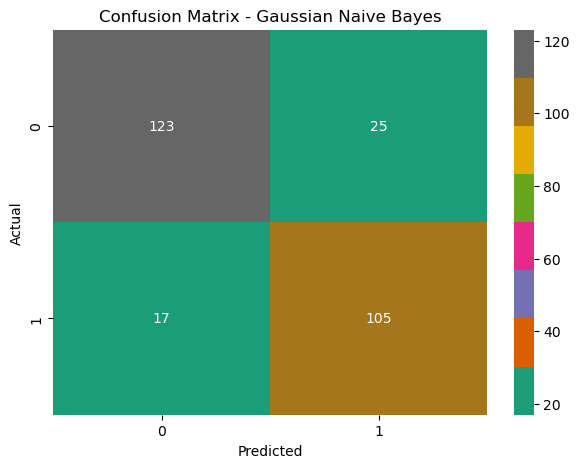

In [40]:
plt.figure(figsize=(7,5))
sns.heatmap(cm,annot=True,fmt='g',cmap='Dark2',xticklabels=[str(c) for c in label_encoder.classes_],
            yticklabels=[str(c) for c in label_encoder.classes_])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Gaussian Naive Bayes')
plt.show()

In [41]:
y_train_pred=gnb.predict(X_train)
y_test_pred=gnb.predict(X_test)
train_accuracy=accuracy_score(y_train,y_train_pred)
test_accuracy=accuracy_score(y_test,y_test_pred)
print("Training Accuracy:",train_accuracy)
print("Testing Accuracy:",test_accuracy)

Training Accuracy: 0.8441558441558441
Testing Accuracy: 0.8444444444444444


In [42]:
GaussianNB(var_smoothing=1e-9)

GaussianNB()

In [43]:
print(gnb.get_params())

{'priors': None, 'var_smoothing': 1e-09}


In [44]:
smoothing_values=[1e-12,1e-10,1e-9,1e-8,1e-7,1e-6,1e-5,1e-4,1e-3,1e-2]
results=[]
for value in smoothing_values:
  model=GaussianNB(var_smoothing=value)
  model.fit(X_train,y_train)
  predicitions=model.predict(X_test)
  accuracy=accuracy_score(y_test,predicitions)
  precision=precision_score(y_test,predicitions)
  recall=recall_score(y_test,predicitions)
  f1=f1_score(y_test,predicitions)
  results.append([value,accuracy,precision,recall,f1])

In [45]:
results_df=pd.DataFrame(
    results,
    columns=['Smoothing Value','Accuracy','Precision','Recall','F1 Score']
)
print(results_df)

   Smoothing Value  Accuracy  Precision    Recall  F1 Score
0     1.000000e-12  0.844444   0.807692  0.860656  0.833333
1     1.000000e-10  0.844444   0.807692  0.860656  0.833333
2     1.000000e-09  0.844444   0.807692  0.860656  0.833333
3     1.000000e-08  0.844444   0.807692  0.860656  0.833333
4     1.000000e-07  0.844444   0.807692  0.860656  0.833333
5     1.000000e-06  0.844444   0.807692  0.860656  0.833333
6     1.000000e-05  0.844444   0.807692  0.860656  0.833333
7     1.000000e-04  0.844444   0.807692  0.860656  0.833333
8     1.000000e-03  0.848148   0.813953  0.860656  0.836653
9     1.000000e-02  0.855556   0.826772  0.860656  0.843373


In [46]:
variance=float(input("Enter variance:"))
skewness=float(input("Enter skewness:"))
curtosis=float(input("Enter curtosis:"))
entropy=float(input("Enter entropy:"))
new_sample=pd.DataFrame({
    'variance':[variance],
    'skewness':[skewness],
    'curtosis':[curtosis],
    'entropy':[entropy]
})
predicition=gnb.predict(new_sample)
print("\nPredicted Class:",predicition)

Enter variance: 5.243
Enter skewness: 11.0272
Enter curtosis: 0.322
Enter entropy: 0.547



Predicted Class: [0]


In [47]:
variance=float(input("Enter variance:"))
skewness=float(input("Enter skewness:"))
curtosis=float(input("Enter curtosis:"))
entropy=float(input("Enter entropy:"))
new_sample=pd.DataFrame({
    'variance':[variance],
    'skewness':[skewness],
    'curtosis':[curtosis],
    'entropy':[entropy]
})
predicition=gnb.predict(new_sample)
print("\nPredicted Class:",predicition)

Enter variance: 7.856
Enter skewness: 9.1254
Enter curtosis: 2.342
Enter entropy: 0.568



Predicted Class: [0]
